In [17]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

[Monique's GitHub link](https://github.com/moniqueallyson/eds220-hwk2.git)


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

<Axes: title={'center': 'Average Salmon Catches by Region from 1878 to 1997'}, xlabel='Region', ylabel='Number of Catch in Thousands of Fish'>

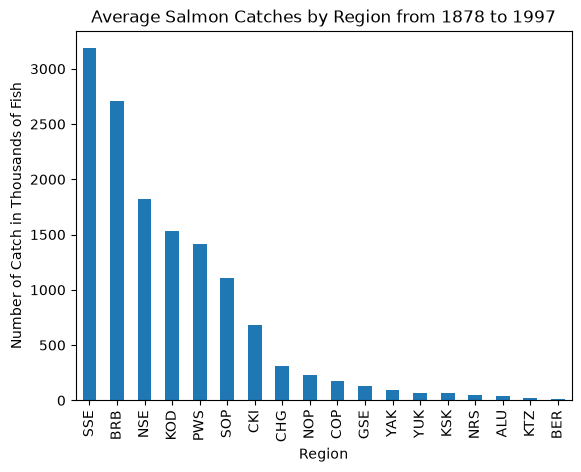

In [18]:
# FINAL CODE
import pandas as pd
catch_data = pd.read_csv('data/salmon_data.csv')

# Update the 400th row from I to 1
catch_data.at[400,'Catch'] = "1"
# Coverting string type of Catch column to Int64
catch_data['Catch'] = catch_data['Catch'].astype(int)
# Create new dataframe with the average of salmon catch by region
avg_region = catch_data.groupby('Region')['Catch'].mean()
# Display bar plot with the new dataframe by descending order
avg_region.sort_values(ascending=False).plot(kind='bar', title='Average Salmon Catches by Region from 1878 to 1997', xlabel='Region', ylabel='Number of Catch in Thousands of Fish')


## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [19]:
# a.

import pandas as pd


catch_data = pd.read_csv('data/salmon_data.csv')


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [20]:
# b.

# Display information about catch_data
catch_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Region        8540 non-null   str  
 1   Year          8540 non-null   int64
 2   notesRegCode  1415 non-null   str  
 3   Species       8540 non-null   str  
 4   Catch         8540 non-null   str  
dtypes: int64(1), str(4)
memory usage: 333.7 KB


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

I chose to use `.info()` since this will give the amount of columns and their names along with their `Dtype`, as well as the number of rows in the dataframe. The information that was obtained was the shape of the dataframe being (8540, 4) with the names of the columns being: Region, Year, Species, notesRegCode (though this has been droped and won't be seen), and Catch.

In [21]:
catch_data.nunique()

Region            18
Year             120
notesRegCode      29
Species            5
Catch           1879
dtype: int64

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [22]:
notes_unique = catch_data['notesRegCode'].unique()

print(notes_unique)

<StringArray>
[                                                                                   nan,
                                                             'Includes Yakutat catches',
                                             'Yakutat catch included in No SE AK catch',
                                   'Estimated from canned production, probably sockeye',
                                                                           'No fishery',
                                'Bering River catches included in Copper River catches',
                                 'Includes Bering River catches; estimated from canned',
                                                        'Includes Bering River catches',
                                 'Coho and pink catch estimated from canned production',
                            'Includes Bering River; coho and pink estimated fro canned',
                                                     'Pink catch estimated from canned',
       

In [23]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [24]:
# Drop notesRegCode column from the dataframe
catch_data = catch_data.drop(columns='notesRegCode')

In [25]:
# Display first few rows to verify the column notesRegCode was dropped
catch_data.head()

,Region,Year,Species,Catch
0,SSE,1886,Chinook,0
1,SSE,1887,Chinook,0
2,SSE,1888,Chinook,0
3,SSE,1889,Chinook,0
4,SSE,1890,Chinook,0


In [26]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


In [35]:
# Display the data types for each column
print(catch_data.dtypes)

Region       str
Year       int64
Species      str
Catch      int64
dtype: object


For the columns `Region` through `Species`, the dtypes are to be expected, except for the column `Catch` since it is categorized as a string depsite the entries being majority numbers, or the expected `int64`.

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [36]:
# Create an error due to the dtype of Catch
catch_data['Catch'].astype('int64')

0         0
1         0
2         0
3         0
4         0
       ... 
8535    135
8536     84
8537     99
8538     68
8539     97
Name: Catch, Length: 8540, dtype: int64

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [29]:
# Display dataframe with Catch starting with 'I'

catch_I = catch_data[catch_data['Catch'].str.startswith('I')]
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [30]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [31]:
# Update the value in the 400th row in the Catch column from I to 1
catch_1 = catch_data.at[400,'Catch'] = "1"

# Print catch_1
catch_1

'1'

In [32]:
# Verify the column Catch no longer has I 
catch_data[catch_data['Catch'].str.startswith('I')]

,Region,Year,Species,Catch


In [13]:
# Verify the column Catch no longer has I with loc
catch_data.loc[400]

Region              GSE
Year               1955
notesRegCode        NaN
Species         Chinook
Catch                 1
Name: 400, dtype: object

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [37]:
# Update the Catch column to int64 from string
catch_data['Catch'] = catch_data['Catch'].astype(int)

# Verify the column type of Catch
catch_column_type = catch_data['Catch'].dtype
catch_column_type

dtype('int64')

In [34]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [38]:
# Create new dataframe with the average of salmon catch by region
avg_region = catch_data.groupby('Region')['Catch'].mean()
avg_region

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64

In [31]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<Axes: title={'center': 'Average Salmon Catches by Region from 1878 to 1997'}, xlabel='Region', ylabel='Number of Catch in Thousands of Fish'>

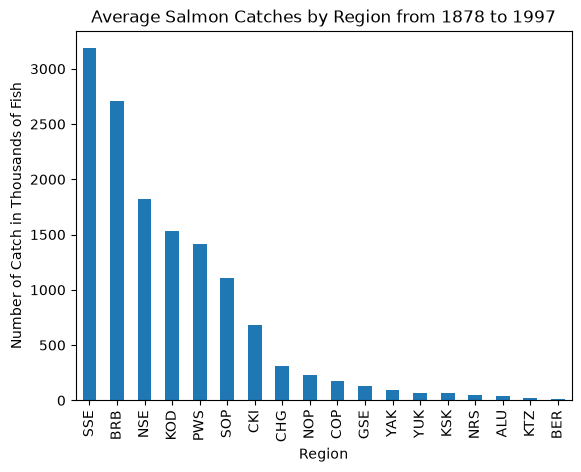

In [9]:
# Display bar plot by descending order of average salmon catch by region provided by avg_region dataframe
avg_region.sort_values(ascending=False).plot(kind='bar',
                                             # Update the title to reflect data shown
                                                        title='Average Salmon Catches by Region from 1878 to 1997',
                                             # Update the x-axis label to Region
                                                        xlabel='Region',
                                             # Update y axis label for the number of salmon caught 
                                                        ylabel='Number of Catch in Thousands of Fish')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

The most catch shown can be found in Southern Southeast Alaska.

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [33]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!